<a href="https://colab.research.google.com/github/venkataratnamb20/quicksilicon/blob/notebooks/vlsi/sensors/psensors_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PySpice


## Setup

In [ ]:
# !apt install pdflatex
!apt install ghostscript texlive-latex-extra cm-super


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
cm-super is already the newest version (0.3.4-17).
texlive-latex-extra is already the newest version (2021.20220204-1).
ghostscript is already the newest version (9.55.0~dfsg1-0ubuntu5.10).
0 upgraded, 0 newly installed, 0 to remove and 29 not upgraded.


In [ ]:
!pip install lcapy

## Schematic


In [ ]:
import lcapy as lp

class Current(lp.exprclasses.ConstantTimeDomainCurrent):
    def __init__(self, val, **assumptions):
        super().__init__(val, **assumptions)

class Voltage(lp.exprclasses.ConstantTimeDomainVoltage):
    def __init__(self, val, **assumptions):
        super().__init__(val, **assumptions)

i1 = Current(10e-6)
v1 = Voltage(10)
i1

1/100000

In [ ]:
class Schematic:
    def __init__(self, netlist: str = ''):
        self.netlist = netlist
        self._circuit = lp.Circuit()

    def add(self, *args):
        self._circuit.add(*args)

    @property
    def circuit(self):
        return self._circuit



In [ ]:
# type(lp.current(10))
# dir(i1)
# i1.units

# Appendix


### Phasor


In [ ]:
from lcapy import *


## Sensor Design

- amplifier
- filter
- adc

**What do I have?**

- sensitivity
- input noise
- accuracy
- output measurement range


**What to find?**
- gain
- filtering

$$ sense\_out = sensitivity * quantity$$
$$ ampout = amp\_gain * sense\_out$$

=================
$$ filter\_out = filter * ampout$$
=================

====================
$$ sigout = ampout $$
$$ noiseout = ampout * filter\_bw $$





### Example

- sensitivity = 26e-6
- noise = 64e-6
- output_range = 180 * 24e-6
- accuracy = 0.3 * 24e-6


In [ ]:
import numpy as np

sensitivity = 26e-6
noise = 64e-6
output_range = 180
accuracy = 0.3
vdd = 2.5

get_snr = lambda sig, noise: 20 * np.log10(sig / noise)

output_range, accuracy,

(180, 0.3)

In [ ]:
get_snr(output_range * sensitivity, accuracy  *sensitivity), get_snr(output_range * sensitivity, noise)

(55.56302500767287, 37.281317581804736)

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


class Sensor:
    def __init__(self, sensitivity, noise_rms):
        self.sensitivity = sensitivity
        self.noise_rms = noise_rms

    def sense(self, vin):
        _vin = np.array(vin)
        _out = self.sensitivity * _vin + np.random.normal(0, self.noise_rms, size=_vin.size)
        return _out

    @staticmethod
    def get_snr(sig, noise_rms):
        return 20 * np.log10(sig / noise_rms)

    def __call__(self, vin):
        return self.sense(vin)

    def __repr__(self):
        return f'Sensor(sensitivity={self.sensitivity}, noise_rms={self.noise_rms})'

    def __str__(self):
        return self.__repr__()

def plot_histogram(data, bins=20, color='blue', edgecolor='black', alpha=0.7):
    """Plots a histogram with formatted bins, mean, and standard deviation.

    Args:
        data: The data to plot.
        bins: The number of bins to use.
        color: The color of the bins.
        edgecolor: The color of the edges of the bins.
        alpha: The opacity of the bins.

    # Example usage
        data = np.random.randn(1000)  # Generate some random data
        plot_histogram(data, bins=20, color='green', edgecolor='white', alpha=0.5)

    """

    # Calculate mean and standard deviation
    mean = np.mean(data)
    mean = float(mean)
    std = np.std(data)
    std = float(std)

    # Plot the histogram
    plt.hist(data, bins=bins, color=color, edgecolor=edgecolor, alpha=alpha)

    # Add mean and standard deviation lines
    plt.axvline(mean, color='red', linestyle='dashed', linewidth=2, label='Mean')
    plt.axvline(mean + std, color='green', linestyle='dashed', linewidth=2, label='Std Dev')
    plt.axvline(mean - std, color='green', linestyle='dashed', linewidth=2)

    # Print mean and standard deviation on the plot
    plt.text(mean + 1.1 * std, 0.9 * plt.ylim()[1], f'Mean: {mean:.2E}', color='red')
    plt.text(mean + 1.1 * std, 0.8 * plt.ylim()[1], f'Std Dev: {std:.2E}', color='green')
    #   plt.text(mean + 0.1 * std, 0.9 * plt.ylim()[1], f'Mean: {mean:.2E}', color='red')
    #   plt.text(mean + 1.1 * std, 0.8 * plt.ylim()[1], f'Std Dev: {std:.2E}', color='green')

    # Set labels and title
    plt.xlabel('Values')
    plt.ylabel('Frequency')
    plt.title('Histogram')
    plt.legend()  # Show legend for mean and std dev lines
    plt.show()



vdd = 1.5
sensitivity = 26e-6
noise_rms = 64e-6
# Define Sensor
sensor = Sensor(sensitivity, noise_rms)

amp_gain = vdd / (sensitivity * output_range)
amp_gain

320.5128205128205

sense SNR: 37.30
ampout SNR: 37.30
filter SNR: 61.67


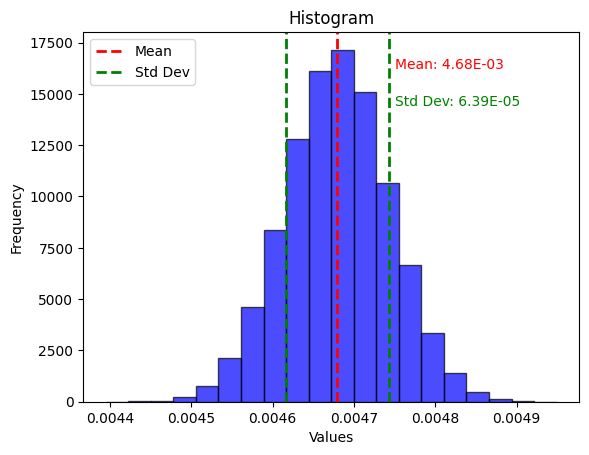

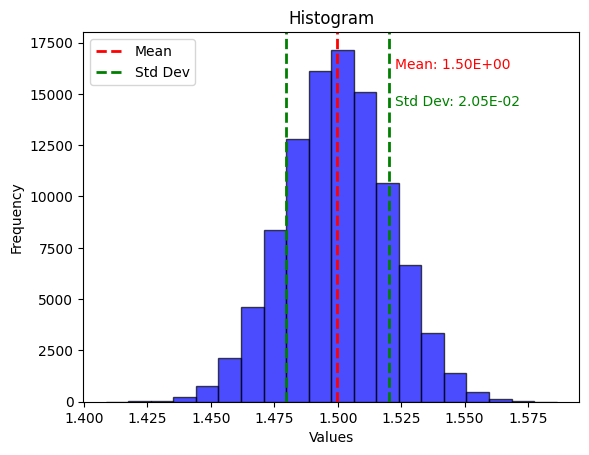

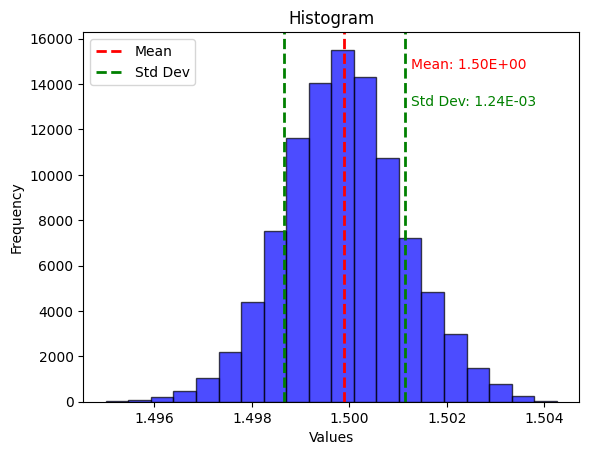

In [ ]:
sense100 = sensor(180*np.ones(100000))
ampout = amp_gain * sense100
sense_df = pd.DataFrame({'sense': sense100, 'ampout': ampout})
sense_df['filter_out'] = sense_df['ampout'].rolling(window=256).mean()
print(f"sense SNR: {Sensor.get_snr(sense_df['sense'].mean(), sense_df['sense'].std()):.2f}")
print(f"ampout SNR: {Sensor.get_snr(sense_df['ampout'].mean(), sense_df['ampout'].std()):.2f}")
print(f"filter SNR: {Sensor.get_snr(sense_df['filter_out'].mean(), sense_df['filter_out'].std()):.2f}")

plot_histogram(sense100)
plot_histogram(ampout)
plot_histogram(sense_df['filter_out'])

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

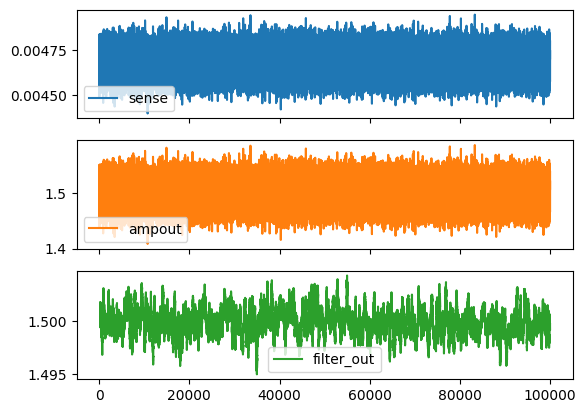

In [ ]:
sense_df.plot(subplots=True)

Max SNR: 64.5855759781431
Min SNR: 37.296092591641084


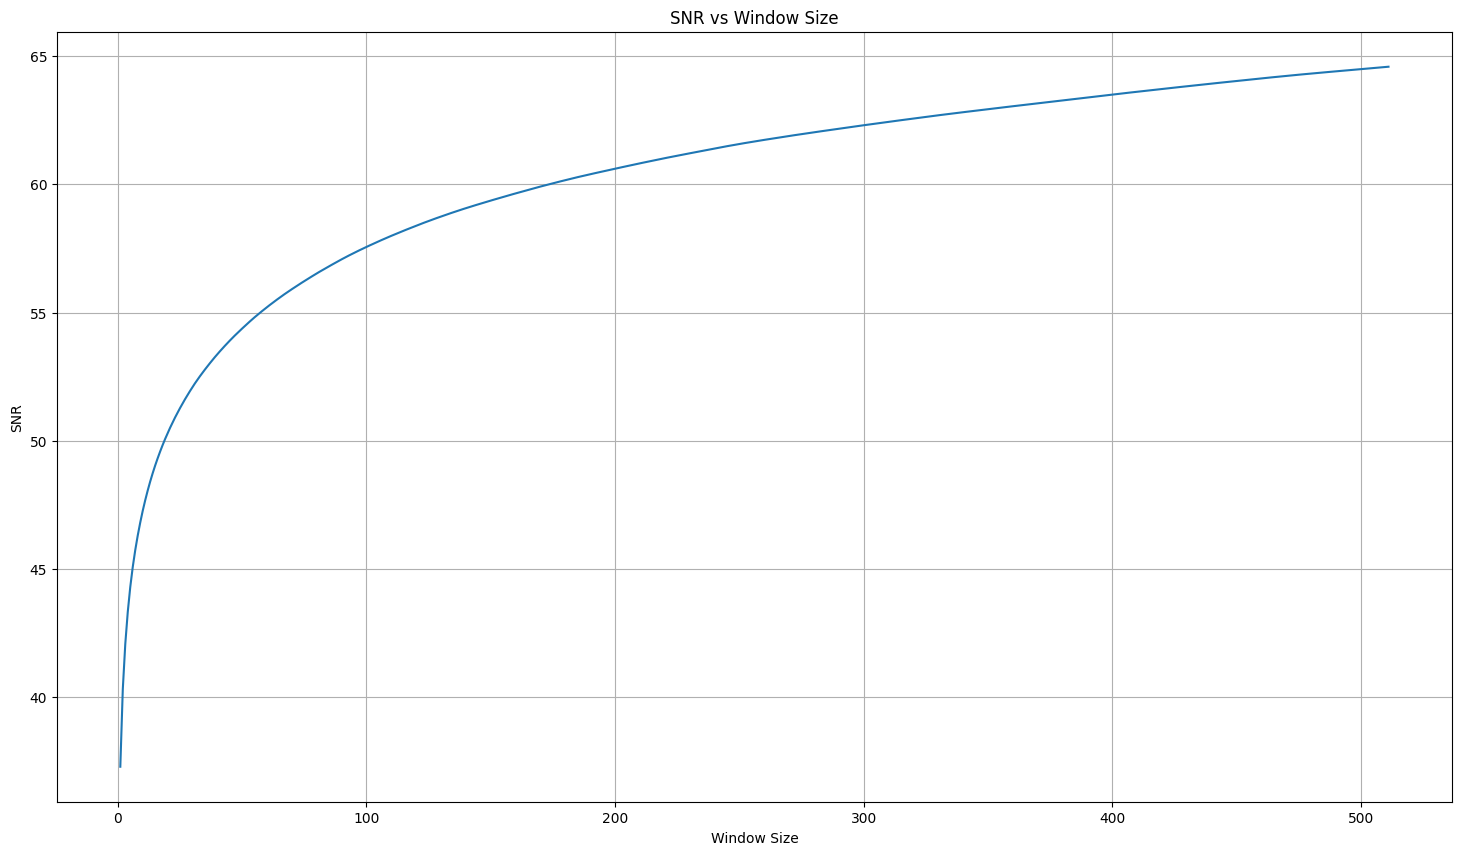

In [ ]:
# find snr for different rolling window
def get_filter_snr(data, window=8):
    filter_out = pd.Series(data).rolling(window=window).mean()
    return Sensor.get_snr(filter_out.mean(), filter_out.std())
# get_filter_snr_vec = np.vectorize(get_filter_snr)
# snr_windows =
windows = np.arange(1, 512)
# get_filter_snr(sense100, window=np.arange(1, 128))
snr_windows = map(lambda x: get_filter_snr(ampout, window=x, ), windows)
snr_windows = list(snr_windows)

fig = plt.figure(figsize=(18, 10))
print(f"Max SNR: {max(snr_windows)}")
print(f"Min SNR: {min(snr_windows)}")
plt.plot(windows, list(snr_windows))
plt.xlabel('Window Size')
plt.ylabel('SNR')
plt.title('SNR vs Window Size')
plt.grid(True, which='both')
plt.show()